# 2. When does the offline metric lie?

Compares AUC with incremental impact on a held-out test set.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

from data import load_criteo, FEATURES

OUTCOME = "conversion"
SEED = 1

df = load_criteo()

strata = df["treatment"].astype(str) + df[OUTCOME].astype(str)
train, test = train_test_split(df, test_size=0.2, random_state=SEED, stratify=strata)

PARAMS = dict(
    n_estimators=150,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.9,
    random_state=SEED,
    verbose=-1,
)

outcome_model = lgb.LGBMClassifier(**PARAMS)
outcome_model.fit(train[FEATURES], train[OUTCOME])

outcome_score = outcome_model.predict_proba(test[FEATURES])[:, 1]
print(f"AUC: {roc_auc_score(test[OUTCOME], outcome_score):.3f}")

AUC: 0.956


In [2]:
treated_train = train[train["treatment"] == 1]
control_train = train[train["treatment"] == 0]

model_treated = lgb.LGBMClassifier(**PARAMS)
model_treated.fit(treated_train[FEATURES], treated_train[OUTCOME])

model_control = lgb.LGBMClassifier(**PARAMS)
model_control.fit(control_train[FEATURES], control_train[OUTCOME])

t_score = (
    model_treated.predict_proba(test[FEATURES])[:, 1]
    - model_control.predict_proba(test[FEATURES])[:, 1]
)

s_features = FEATURES + ["treatment"]
s_model = lgb.LGBMClassifier(**PARAMS)
s_model.fit(train[s_features], train[OUTCOME])

s_score = (
    s_model.predict_proba(test[FEATURES].assign(treatment=1))[:, 1]
    - s_model.predict_proba(test[FEATURES].assign(treatment=0))[:, 1]
)

scores = {
    "Outcome model": outcome_score,
    "T-learner": t_score,
    "S-learner": s_score,
}

for name, score in scores.items():
    print(f"{name} AUC: {roc_auc_score(test[OUTCOME], score):.3f}")


Outcome model AUC: 0.956
T-learner AUC: 0.774
S-learner AUC: 0.944


In [3]:
TOP_SHARES = [0.05, 0.1, 0.2, 0.3, 0.5, 1.0]
rng = np.random.default_rng(SEED)

y = test[OUTCOME].to_numpy()
t = test["treatment"].to_numpy()
scores["Random"] = rng.random(len(test))

def extra_conversions(score):
    # Random tie-break, because some users have identical features.
    order = np.lexsort((rng.random(len(score)), -score))
    y_sorted, t_sorted = y[order], t[order]

    n_treated = np.cumsum(t_sorted == 1)
    n_control = np.cumsum(t_sorted == 0)
    conv_treated = np.cumsum(y_sorted * (t_sorted == 1))
    conv_control = np.cumsum(y_sorted * (t_sorted == 0))

    with np.errstate(divide="ignore", invalid="ignore"):
        effect = conv_treated / n_treated - conv_control / n_control

    return effect * (n_treated + n_control)

curves = {name: extra_conversions(score) for name, score in scores.items()}
total = curves["Outcome model"][-1]

rows = []
for name, curve in curves.items():
    row = {"model": name, "AUC": roc_auc_score(y, scores[name])}
    for share in TOP_SHARES:
        position = int(share * len(curve)) - 1
        row[f"top {share:.0%}"] = curve[position] / total * 100
    rows.append(row)

results = pd.DataFrame(rows).set_index("model")
results.round(3)


,AUC,top 5%,top 10%,top 20%,top 30%,top 50%,top 100%
model,,,,,,,
Outcome model,0.956,58.416,75.250,86.085,91.561,96.215,100.0
T-learner,0.774,53.152,65.555,76.521,82.223,85.524,100.0
S-learner,0.944,54.054,71.739,85.691,91.283,95.583,100.0
Random,0.503,4.866,10.377,18.820,27.437,50.315,100.0


In [4]:
del train, test

TOP_SHARES = [0.05, 0.1, 0.2, 0.3, 0.5, 1.0]

def compare_models(outcome, seed):
    strata = df["treatment"].astype(str) + df[outcome].astype(str)
    train, test = train_test_split(df, test_size=0.2, random_state=seed, stratify=strata)

    params = {**PARAMS, "random_state": seed}

    def fit(data, columns):
        model = lgb.LGBMClassifier(**params)
        return model.fit(data[columns], data[outcome])

    def predict(model, X):
        return model.predict_proba(X)[:, 1]

    X_test = test[FEATURES]
    treated = train[train["treatment"] == 1]
    control = train[train["treatment"] == 0]
    s_model = fit(train, FEATURES + ["treatment"])

    rng = np.random.default_rng(seed)
    scores = {
        "Outcome model": predict(fit(train, FEATURES), X_test),
        "T-learner": predict(fit(treated, FEATURES), X_test) - predict(fit(control, FEATURES), X_test),
        "S-learner": predict(s_model, X_test.assign(treatment=1)) - predict(s_model, X_test.assign(treatment=0)),
        "Random": rng.random(len(test)),
    }

    y = test[outcome].to_numpy()
    t = test["treatment"].to_numpy()

    rows = []
    for name, score in scores.items():
        order = np.lexsort((rng.random(len(score)), -score))
        y_sorted, t_sorted = y[order], t[order]

        n_treated = np.cumsum(t_sorted == 1)
        n_control = np.cumsum(t_sorted == 0)
        count_treated = np.cumsum(y_sorted * (t_sorted == 1))
        count_control = np.cumsum(y_sorted * (t_sorted == 0))

        with np.errstate(divide="ignore", invalid="ignore"):
            curve = (count_treated / n_treated - count_control / n_control) * (n_treated + n_control)

        row = {"outcome": outcome, "seed": seed, "model": name, "AUC": roc_auc_score(y, score)}
        for share in TOP_SHARES:
            row[f"top {share:.0%}"] = curve[int(share * len(curve)) - 1] / curve[-1] * 100
        rows.append(row)

    print(f"Finished {outcome}, split {seed}")
    return pd.DataFrame(rows)

runs = [("conversion", s) for s in [1, 2, 3, 4, 5]] + [("visit", s) for s in [1, 2, 3]]
all_results = pd.concat([compare_models(o, s) for o, s in runs], ignore_index=True)

summary = (
    all_results.groupby(["outcome", "model"], sort=False)
    .mean(numeric_only=True)
    .drop(columns="seed")
    .round(3)
)
summary


Finished conversion, split 1
Finished conversion, split 2
Finished conversion, split 3
Finished conversion, split 4
Finished conversion, split 5
Finished visit, split 1
Finished visit, split 2
Finished visit, split 3


AUC  top 5%  top 10%  top 20%  top 30%  top 50%  \
outcome    model                                                              
conversion Outcome model  0.958  56.463   72.107   85.442   91.916   96.553   
           T-learner      0.767  50.470   64.085   76.498   80.781   84.448   
           S-learner      0.947  54.182   70.123   85.126   91.174   96.070   
           Random         0.500   5.816   11.573   20.169   30.510   53.114   
visit      Outcome model  0.947  26.900   48.702   73.094   83.733   94.544   
           T-learner      0.785  43.059   58.528   76.056   85.875   94.883   
           S-learner      0.879  44.812   60.654   74.610   83.619   94.729   
           Random         0.500   5.075    9.523   19.249   28.980   48.507   

                          top 100%  
outcome    model                    
conversion Outcome model     100.0  
           T-learner         100.0  
           S-learner         100.0  
           Random            100.0  
visit      Outcome model     100.0  
           T-learner         100.0  
           S-learner         100.0  
           Random            100.0

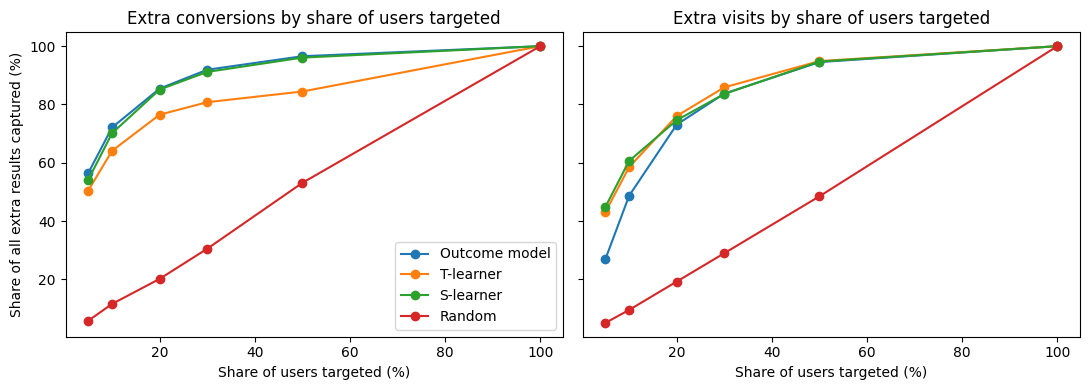

In [5]:
import matplotlib.pyplot as plt

share_columns = ["top 5%", "top 10%", "top 20%", "top 30%", "top 50%", "top 100%"]
share_values = [5, 10, 20, 30, 50, 100]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, outcome in zip(axes, ["conversion", "visit"]):
    for model in ["Outcome model", "T-learner", "S-learner", "Random"]:
        ax.plot(share_values, summary.loc[(outcome, model), share_columns], marker="o", label=model)
    ax.set_title(f"Extra {outcome}s by share of users targeted")
    ax.set_xlabel("Share of users targeted (%)")

axes[0].set_ylabel("Share of all extra results captured (%)")
axes[0].legend()
plt.tight_layout()
plt.savefig("../reports/auc_vs_incremental.png", dpi=150)
plt.show()



Result: Averaged over repeated random splits (5 for conversion, 3 for visit). For conversion, the outcome model has the best AUC (0.958) and captures about 72% of extra conversions in the top 10% of users, close to the S-learner (70%) and ahead of the T-learner (64%). For visits, AUC again favours the outcome model (0.947), but it captures only about 49% of extra visits in the top 10%, against 61% for the S-learner and 59% for the T-learner. By the top 20%, the models are about level. So a high AUC does not guarantee the most incremental impact, especially when targeting a small group. Limits: the models have only light tuning, all splits come from the same pooled dataset, the features are anonymised, and the data has no costs. I also can't yet say why the two outcomes differ.